# Spike counting and seizure intensity

Detect and manually review interictal spikes on the PTZ challenge day, then summarize spike amplitude and Racine-seizure RMS (z-scored to each animal's baseline). Channel of interest is ipsilateral cortex (channel 1 for 1103, channel 2 otherwise).

## Imports

In [2]:
from pathlib import Path

import mne
import numpy as np

from _tbi_pte.subject import EEGSubject
from _tbi_pte.utils import select_data_segment

seizure_colors = {
    "racine1": "#4C72B0",
    "racine2": "#55A868",
    "racine3": "#C44E52",
    "racine4": "#8172B2",
    "racine5": "#CCB974",
    "racine6": "#64B5CD",
}

## Cohort and recording days

Each entry is `(group, [date tags])`. Baseline, PTZ-challenge, and (when present) post-challenge files are listed so spike detection can use the baseline marker and restrict search to the challenge window.

In [3]:
ptz_subjects = {
    '1103': ("unassigned", ['05_30_2024_part1','05_30_2024_part2']),
    '1108': ("unassigned", ['05_31_2024_part1','05_31_2024_part2']),
    '1120': ("unassigned", ['05_31_2024_part1','05_31_2024_part2']),
    '1255': ("unassigned", ['03_07_2025_part1','03_07_2025_part2']),
    '1261': ("unassigned", ['04_09_2025_part1','04_09_2025_part2', '04_09_2025_part3']),
    '1262': ("unassigned", ['04_09_2025_part1','04_09_2025_part2', '04_09_2025_part3']),
    '1273': ("unassigned", ['04_19_2025_part2','04_21_2025_part1', '04_21_2025_part2']),
    '1315': ("unassigned", ['07_18_2025_part1','07_18_2025_part2', '07_18_2025_part3']),
    '1345': ("unassigned", ['08_08_2025_part1','08_08_2025_part2', '08_08_2025_part3']),
    '1347': ("unassigned", ['08_08_2025_part1','08_08_2025_part2', '08_08_2025_part3']),
    '1387': ("unassigned", ['12_15_2025_part1','12_15_2025_part2', '12_15_2025_part3']),
    '1396': ("unassigned", ['01_15_2026_part1','01_15_2026_part2', '01_15_2026_part3']),
    '1400': ("unassigned", ['01_26_2026_part1','01_26_2026_part2', '01_26_2026_part3']),
    '1401': ("unassigned", ['01_26_2026_part1','01_26_2026_part2', '01_26_2026_part3']),
    '1402': ("unassigned", ['01_26_2026_part1','01_26_2026_part2', '01_26_2026_part3']),
    '1416': ("unassigned", ['03_26_2026_part1','03_26_2026_part2', '03_26_2026_part3']),
    '1417': ("unassigned", ['03_26_2026_part1','03_26_2026_part2', '03_26_2026_part3']),
    '1419': ("unassigned", ['03_27_2026_part1','03_27_2026_part2', '03_27_2026_part3']),
    '1420': ("unassigned", ['03_27_2026_part1','03_27_2026_part2', '03_27_2026_part3']),
    '1438': ("unassigned", ['04_20_2026_part1','04_20_2026_part2', '04_20_2026_part3']),
    '1442': ("unassigned", ['05_01_2026_part1','05_01_2026_part2', '05_01_2026_part3']),
    '1443': ("unassigned", ['05_01_2026_part1','05_01_2026_part2', '05_01_2026_part3']),
    '1445': ("unassigned", ['05_07_2026_part1','05_07_2026_part2', '05_07_2026_part3'])
    }

## Load, filter, and assign channel of interest

Load EDF and markers, then bandpass 1–50 Hz. Animals `1402`, `1420`, and `1445` are skipped because EEG quality was insufficient for spike detection. Ipsilateral cortex is channel index `0` for 1103 and `1` otherwise.

In [27]:
data_dir = Path("D:/RatEEG/exported_data/")
filename_flag = (5, 21)
rescale_ids = ['1255', '1273']

rats = []

# the following skipped animals did not have good enough quality EEG for spike detection
bad_EEG1 = ['1262', '1401', '1442']
bad_EEG2 = ['1420','1445']

bad_all = ['1313','1386','1388','1390','1393','1399','1402', '1417','1418','1440']

skip_ids = bad_all + bad_EEG2

for id, rat in ptz_subjects.items():

    # skip 1402 eeg was too p
    if skip_ids and id in skip_ids:
        continue

    ratID = id
    group = rat[0]
    dates = rat[1]
    # Ispi - channel 1 
    coi = 0 if ratID == '1103' else 1
    # Contra - channel 0
    # coi = 1 if ratID == '1103' else 0
    rat = EEGSubject(ratID, group, data_dir=data_dir / ratID, coi=coi)

    rescale_eeg = 1e-3 if ratID in rescale_ids else None
    rat.load_eeg(dates=dates, filename_flag=filename_flag, rescale_eeg=rescale_eeg)
    rat.load_markers(dates=dates, filename_flag=filename_flag)
    rat.preprocess_data(down_sample_rate=None, high_pass_filter=1, low_pass_filter=50)

    rats.append(rat)
    print("Completed loading subject: ", rat.subject_id)

Loading 05_30_2024_part1
Extracting EDF parameters from D:\RatEEG\exported_data\1103\1103_05_30_2024_part1_rawEEG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 18229999  =      0.000 ... 36459.998 secs...
Loading 05_30_2024_part2
Extracting EDF parameters from D:\RatEEG\exported_data\1103\1103_05_30_2024_part2_rawEEG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 24444999  =      0.000 ... 48889.998 secs...
Loading markers for subject 1103 and date 05_30_2024_part1
Loading markers for subject 1103 and date 05_30_2024_part2


C:\Users\udeozomi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
C:\Users\udeozomi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Applied bandpass filter: 1-50Hz
Applied bandpass filter: 1-50Hz
Completed loading subject:  1103
Loading 05_31_2024_part1
Extracting EDF parameters from D:\RatEEG\exported_data\1108\1108_05_31_2024_part1_rawEEG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 16824999  =      0.000 ... 33649.998 secs...
Loading 05_31_2024_part2
Extracting EDF parameters from D:\RatEEG\exported_data\1108\1108_05_31_2024_part2_rawEEG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 2844999  =      0.000 ...  5689.998 secs...
Loading markers for subject 1108 and date 05_31_2024_part1
Loading markers for subject 1108 and date 05_31_2024_part2


C:\Users\udeozomi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
C:\Users\udeozomi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Applied bandpass filter: 1-50Hz
Applied bandpass filter: 1-50Hz
Completed loading subject:  1108
Loading 05_31_2024_part1
Extracting EDF parameters from D:\RatEEG\exported_data\1120\1120_05_31_2024_part1_rawEEG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 16824999  =      0.000 ... 33649.998 secs...
Loading 05_31_2024_part2
Extracting EDF parameters from D:\RatEEG\exported_data\1120\1120_05_31_2024_part2_rawEEG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 2844999  =      0.000 ...  5689.998 secs...
Loading markers for subject 1120 and date 05_31_2024_part1
Loading markers for subject 1120 and date 05_31_2024_part2


C:\Users\udeozomi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
C:\Users\udeozomi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


... (37 outputs left out)

C:\Users\udeozomi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
C:\Users\udeozomi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Applied bandpass filter: 1-50Hz
Applied bandpass filter: 1-50Hz
Completed loading subject:  1442
Loading 05_01_2026_part1
Extracting EDF parameters from D:\RatEEG\exported_data\1443\1443_05_01_2026_part1_rawEEG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 22709999  =      0.000 ... 45419.998 secs...
Loading 05_01_2026_part2
Extracting EDF parameters from D:\RatEEG\exported_data\1443\1443_05_01_2026_part2_rawEEG.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 20284999  =      0.000 ... 40569.998 secs...
Loading markers for subject 1443 and date 05_01_2026_part1
Loading markers for subject 1443 and date 05_01_2026_part2


C:\Users\udeozomi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
C:\Users\udeozomi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Applied bandpass filter: 1-50Hz
Applied bandpass filter: 1-50Hz
Completed loading subject:  1443


## Automatic spike detection

On the PTZ-challenge file (`dates[1]`), detect peaks of `|z|` (threshold = 5, minimum 1 s between peaks) from recording start through 15 min after the last PTZ dose. Peaks inside Racine windows are discarded. Detections are stored on the subject as `(sample_index, voltage, signed_z)`.

Detecting spikes for 1103 on 05_30_2024_part2
Removed 76 spikes from seizure/s
Detected 56 spikes


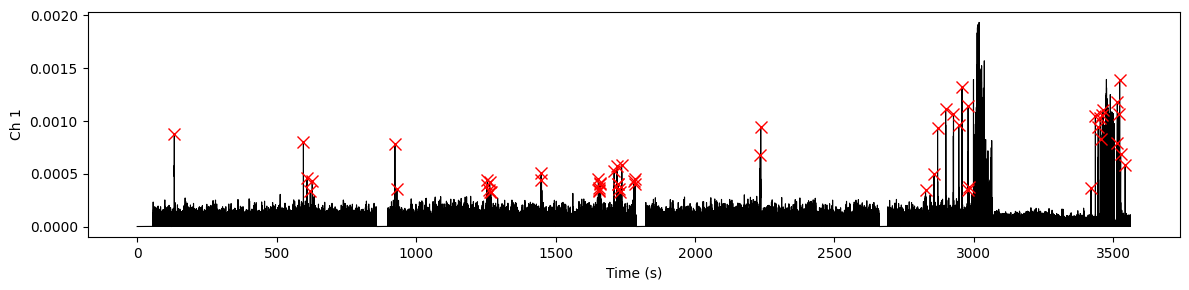

Detecting spikes for 1108 on 05_31_2024_part2
Removed 29 spikes from seizure/s
Detected 105 spikes


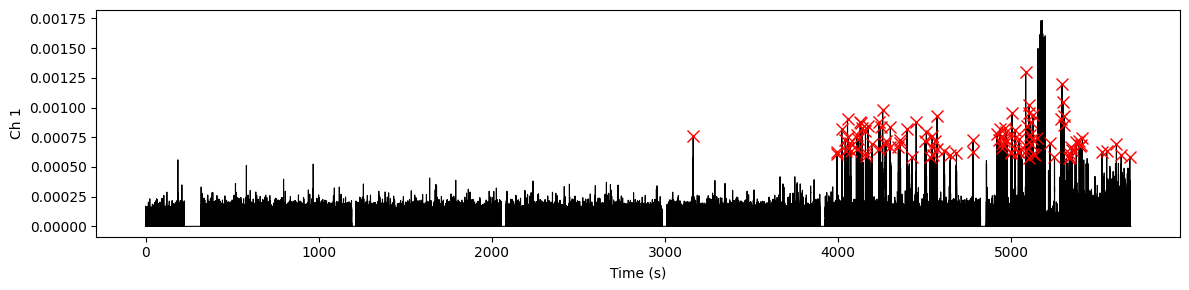

Detecting spikes for 1120 on 05_31_2024_part2
Removed 91 spikes from seizure/s
Detected 111 spikes


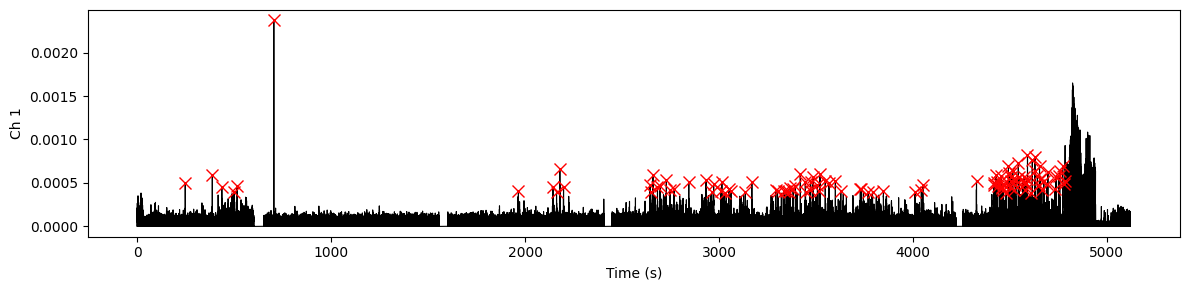

Detecting spikes for 1255 on 03_07_2025_part2
Removed 69 spikes from seizure/s
Detected 139 spikes


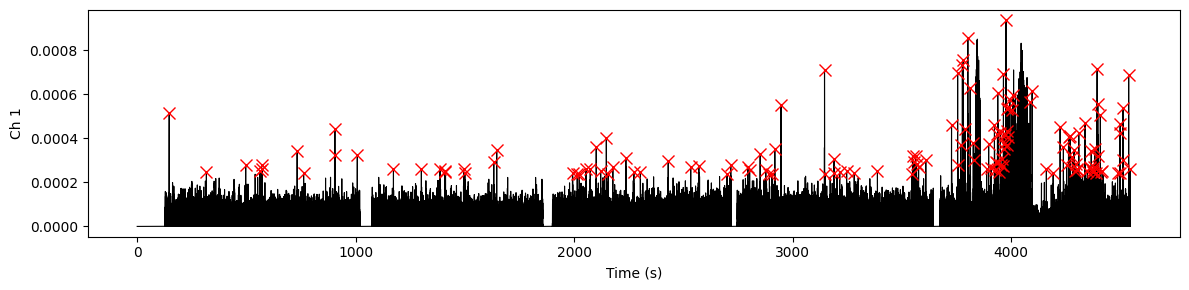

Detecting spikes for 1261 on 04_09_2025_part2
Removed 29 spikes from seizure/s
Detected 316 spikes


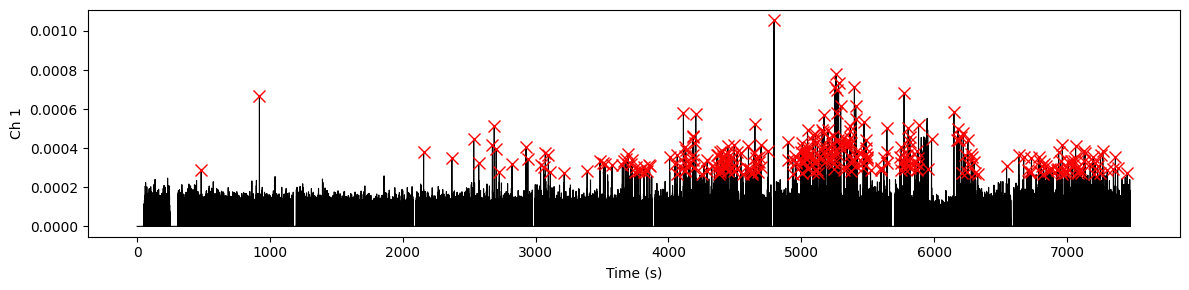

Detecting spikes for 1262 on 04_09_2025_part2
Removed 107 spikes from seizure/s
Detected 581 spikes


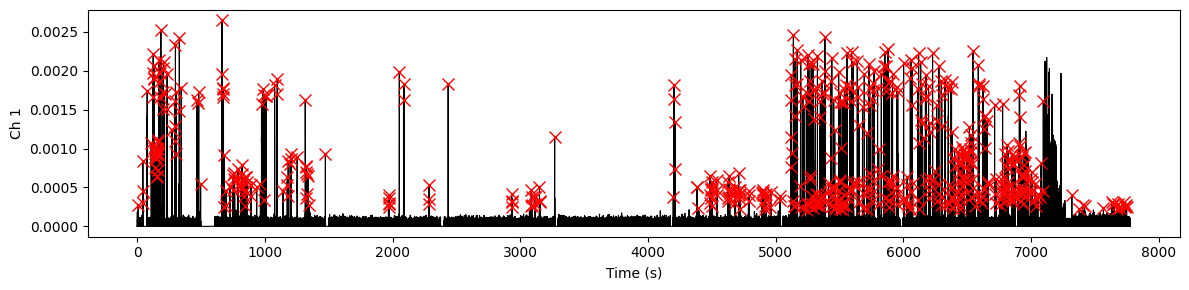

Detecting spikes for 1273 on 04_21_2025_part1
Removed 24 spikes from seizure/s
Detected 641 spikes


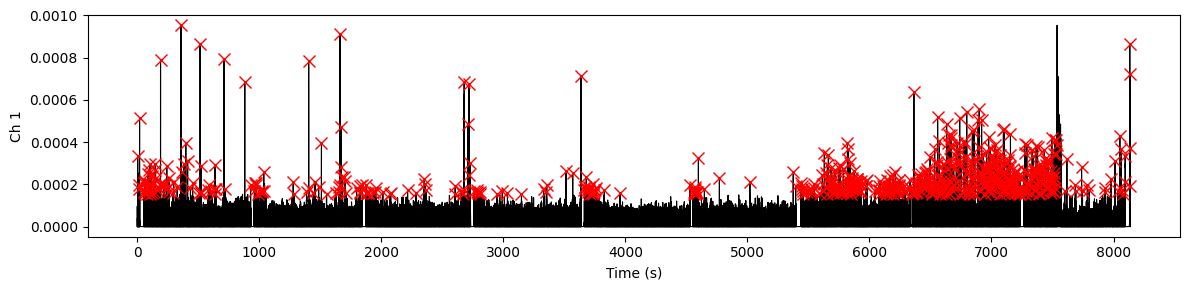

Detecting spikes for 1315 on 07_18_2025_part2
Removed 74 spikes from seizure/s
Detected 69 spikes


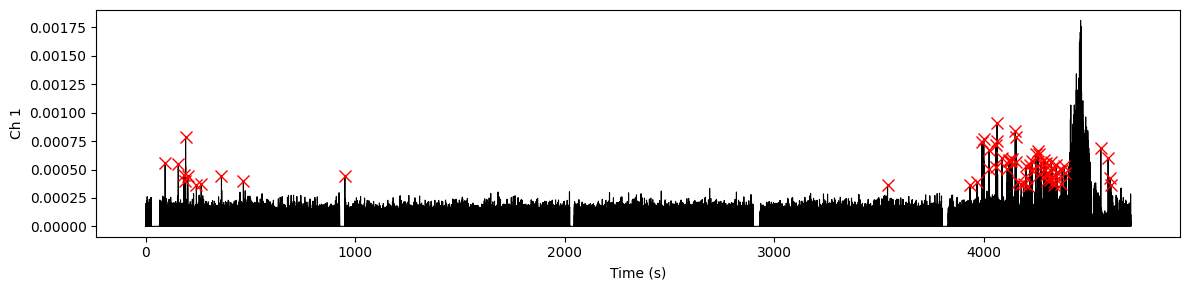

Detecting spikes for 1345 on 08_08_2025_part2
Removed 82 spikes from seizure/s
Detected 172 spikes


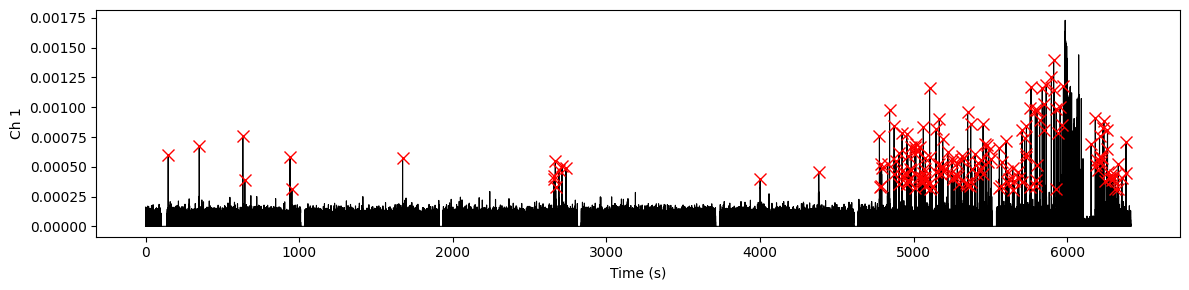

Detecting spikes for 1347 on 08_08_2025_part2
Removed 136 spikes from seizure/s
Detected 256 spikes


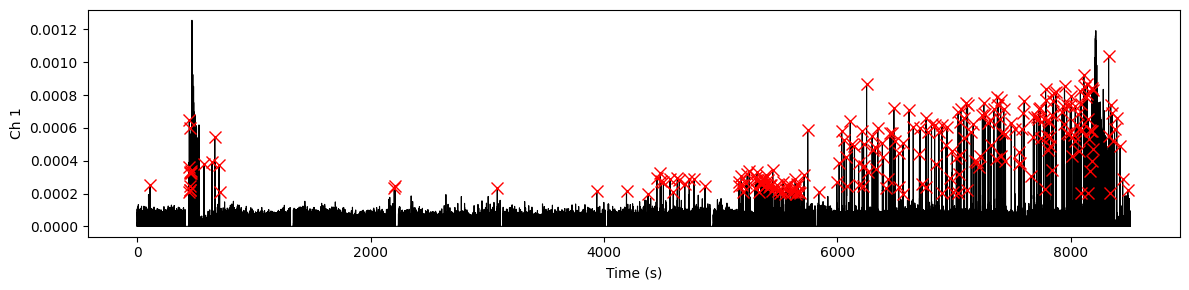

Detecting spikes for 1387 on 12_15_2025_part2
Removed 0 spikes from seizure/s
Detected 618 spikes


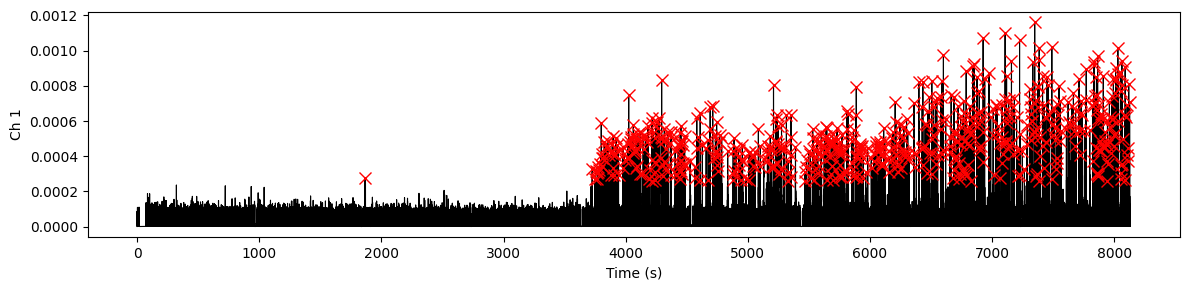

Detecting spikes for 1396 on 01_15_2026_part2
Removed 25 spikes from seizure/s
Detected 149 spikes


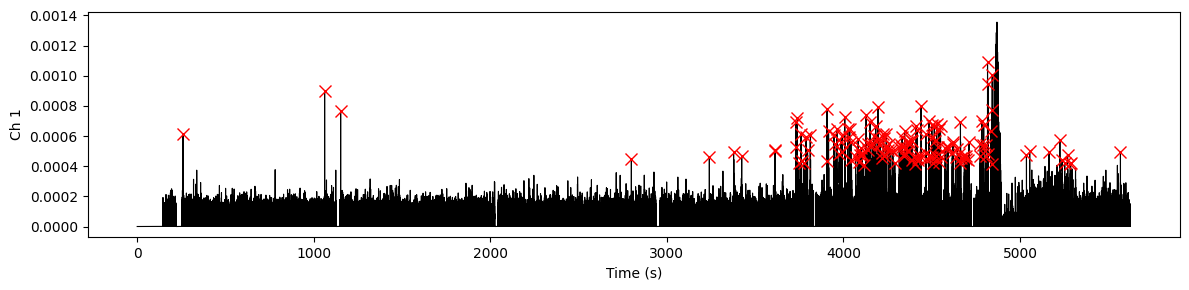

Detecting spikes for 1400 on 01_26_2026_part2
Removed 90 spikes from seizure/s
Detected 34 spikes


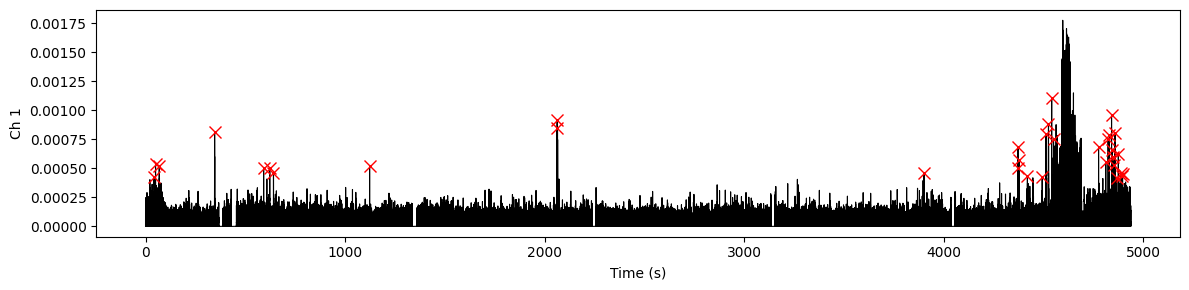

Detecting spikes for 1401 on 01_26_2026_part2
Removed 89 spikes from seizure/s
Detected 2202 spikes


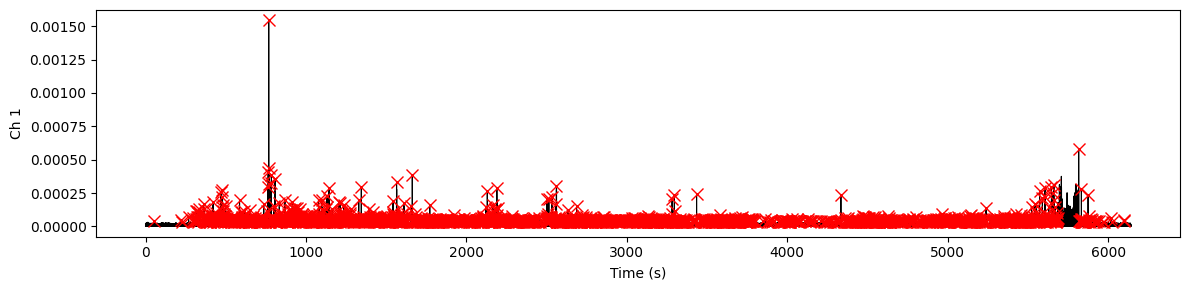

Detecting spikes for 1416 on 03_26_2026_part2
Removed 64 spikes from seizure/s
Detected 19 spikes


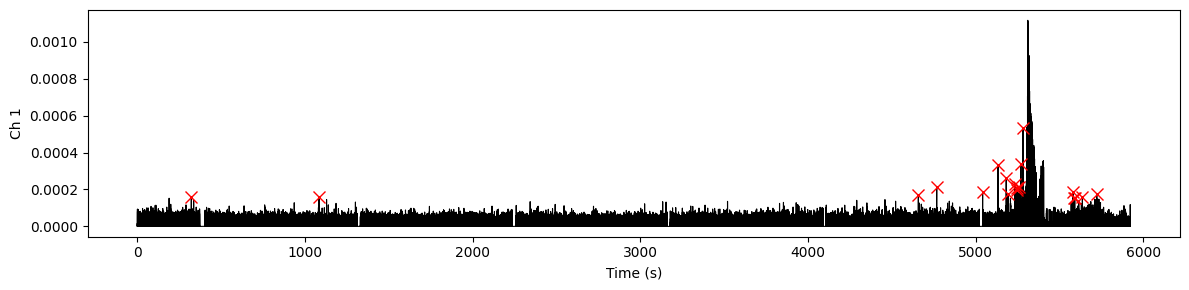

Detecting spikes for 1419 on 03_27_2026_part2
Removed 53 spikes from seizure/s
Detected 40 spikes


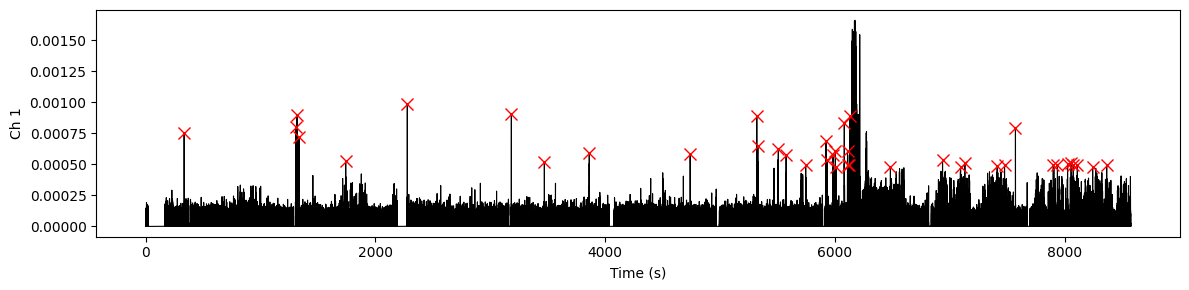

Detecting spikes for 1438 on 04_20_2026_part2
Removed 30 spikes from seizure/s
Detected 233 spikes


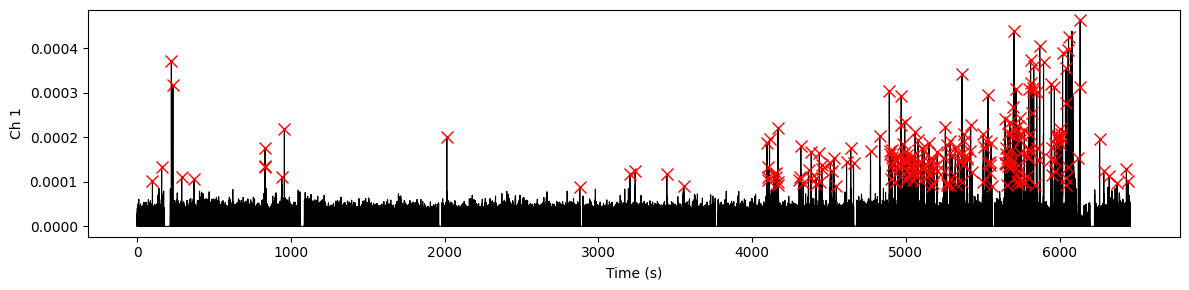

Detecting spikes for 1442 on 05_01_2026_part2
Removed 26 spikes from seizure/s
Detected 343 spikes


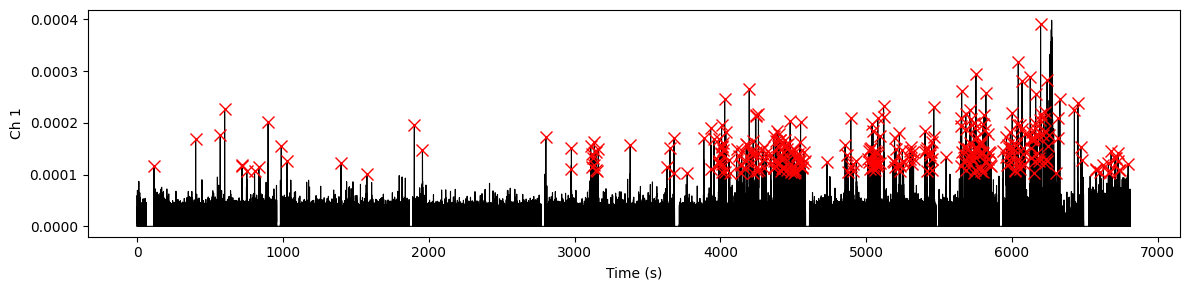

Detecting spikes for 1443 on 05_01_2026_part2
Detected 127 spikes


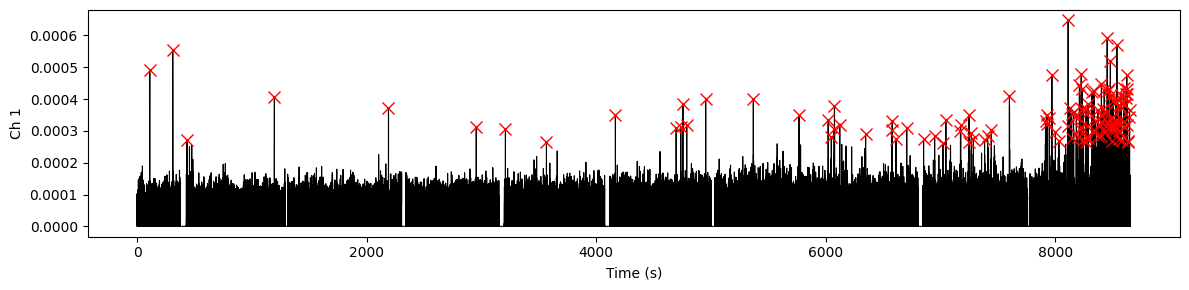

In [33]:
%matplotlib inline

for r in rats: # rat of interest

    # set channel of interest to ipsi (EEG2, idx = 1); contralateral (EEG1, idx = 0). 1103 was swapped
    r.coi = 1 if ratID == '1103' else 0 
    
    dates = sorted(list(r.preprocessed.keys()))
    ptz_day = dates[1] #ptz challenge period
    fs = r.preprocessed[ptz_day].info['sfreq']

    spike_buffer = 1 # seconds
    threshold = 5 # z-score threshold for spike detection

    # We only want to look for spike from the beginning to 15 mins past the final ptz dose
    lastPTZ_time = [p[0] for p in r.markers[ptz_day]['ptz']][-1] # get the time of the last ptz dose
    lastPTZ_sample = int(lastPTZ_time * fs) # convert to samples
    extra_time = 15 * 60 * fs # get the sample 15 minutes past last ptz
    time_range = (0, lastPTZ_sample + extra_time) # set the time range to look for spikes

    r.detect_spikes(
        day=ptz_day, threshold=threshold,
        spike_buffer=spike_buffer, plot=True,
        remove_seizures=True, time_range=time_range
        )

## Manual spike review

Interactive inclusion/exclusion of automatic detections (Qt backend). All detections start included; `n` excludes, `y` includes, arrows step, `q` quits. Returns `(peak_index, spike_voltage, zscored_voltage)`.

In [36]:
%matplotlib qt

for r in rats: # rat of interest
    dates = sorted(list(r.preprocessed.keys()))
    ptz_day = dates[1] #ptz challenge period
    spikes = r.detected_spikes[ptz_day]

    r.review_spikes(
        day=ptz_day, spikes=spikes, short_window=1, long_window=60, zscore=True
        )

Reviewing spikes for 1103 on 05_30_2024_part2
Kept 45 / 56 included spikes
Saving spikes for 1103 on 05_30_2024_part2
Saved 45 spikes to D:\RatEEG\exported_data\1103\1103_05_30_2024_part2_spikes_contralateral.csv
Reviewing spikes for 1108 on 05_31_2024_part2
Kept 105 / 105 included spikes
Saving spikes for 1108 on 05_31_2024_part2
Saved 105 spikes to D:\RatEEG\exported_data\1108\1108_05_31_2024_part2_spikes_contralateral.csv
Reviewing spikes for 1120 on 05_31_2024_part2
Kept 106 / 111 included spikes
Saving spikes for 1120 on 05_31_2024_part2
Saved 106 spikes to D:\RatEEG\exported_data\1120\1120_05_31_2024_part2_spikes_contralateral.csv


## Save or reload included spikes

Set `load`, `review`, and/or `save` to persist the curated spike list as `{id}_{date}_spikes.csv` under each animal's export folder, or to re-review a previously saved list.

Reviewing spikes for 1255 on 03_07_2025_part2


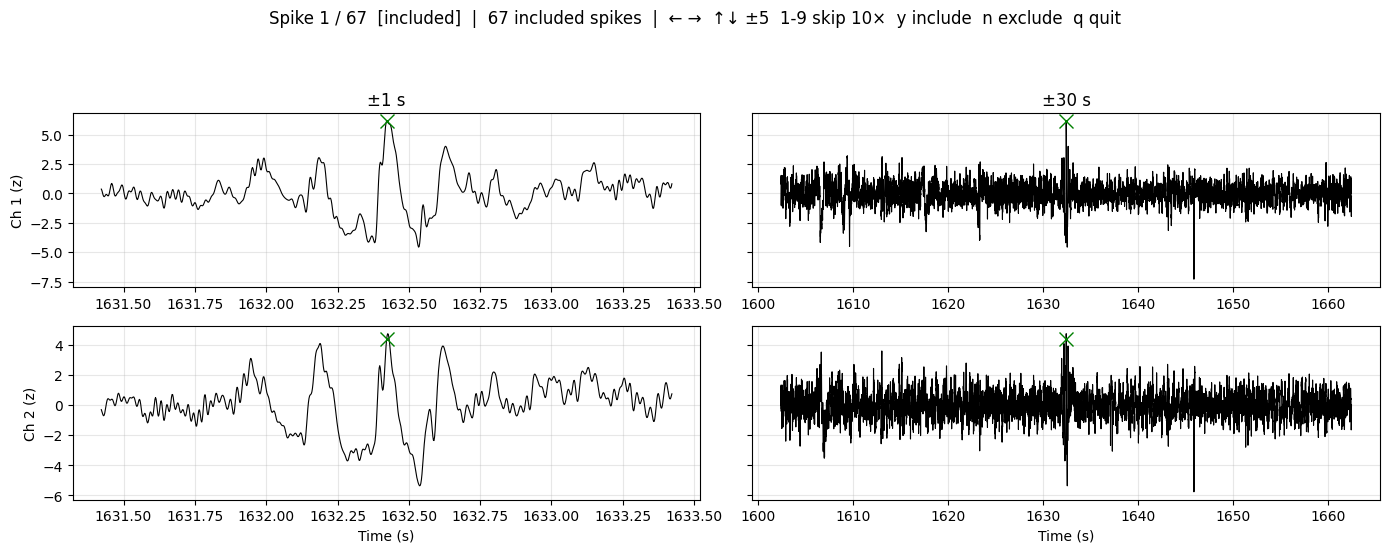

Kept 67 / 67 included spikes
Reviewing spikes for 1261 on 04_09_2025_part2


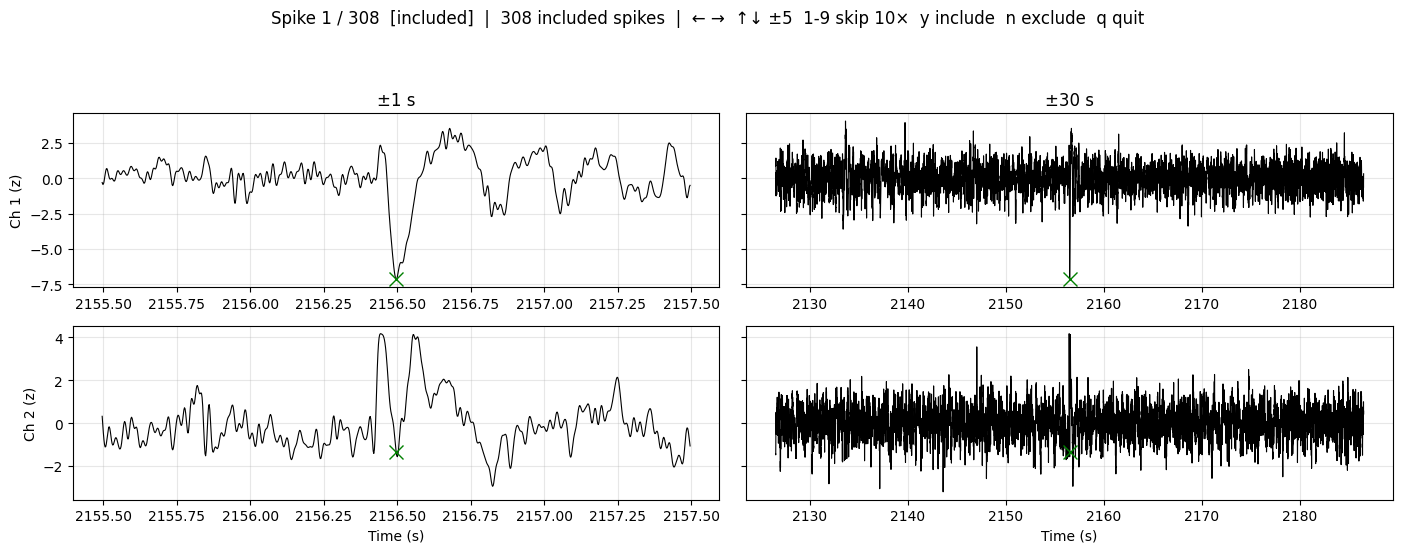

Kept 308 / 308 included spikes
Reviewing spikes for 1273 on 04_21_2025_part1


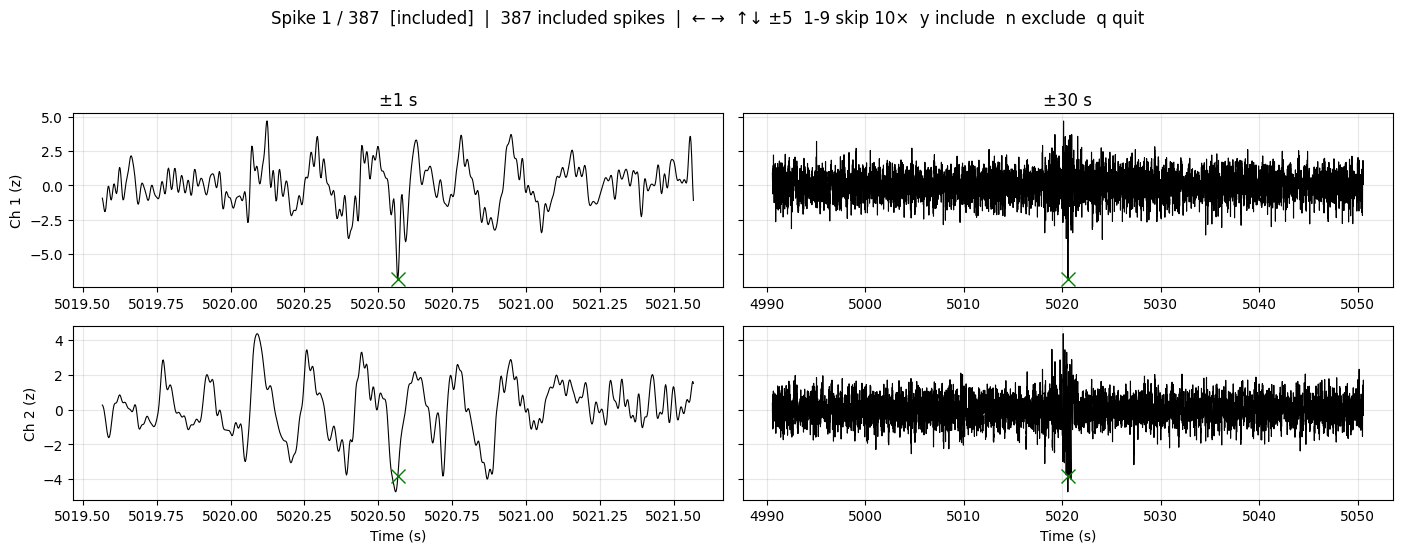

Kept 387 / 387 included spikes
Reviewing spikes for 1315 on 07_18_2025_part2


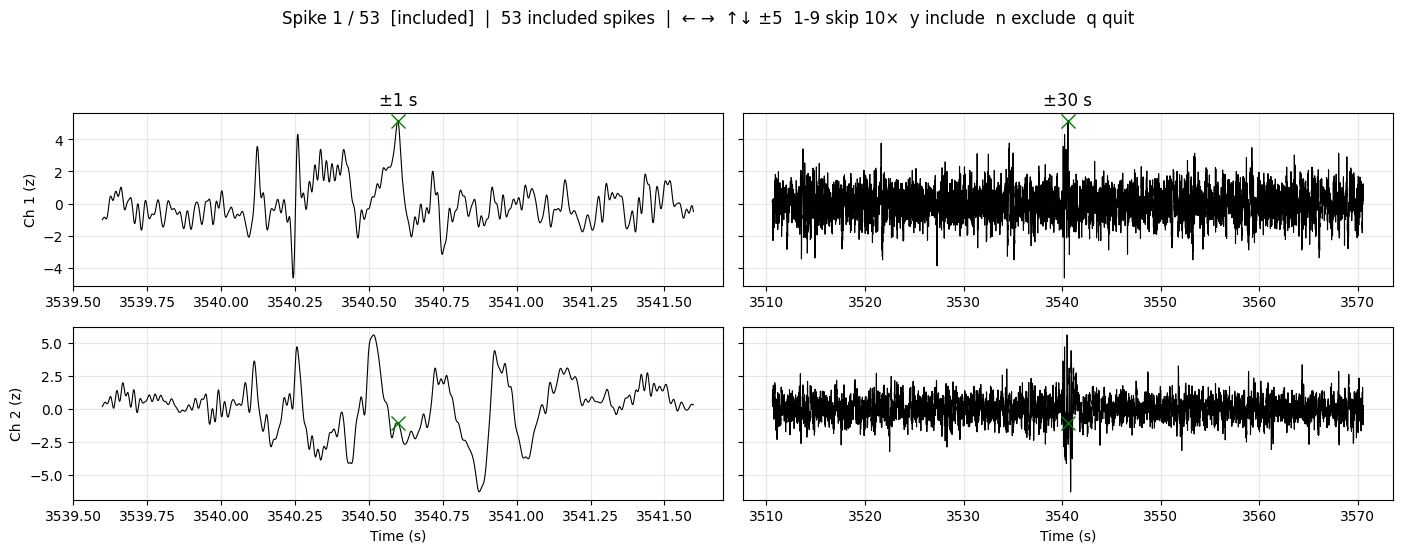

Kept 53 / 53 included spikes
Reviewing spikes for 1345 on 08_08_2025_part2


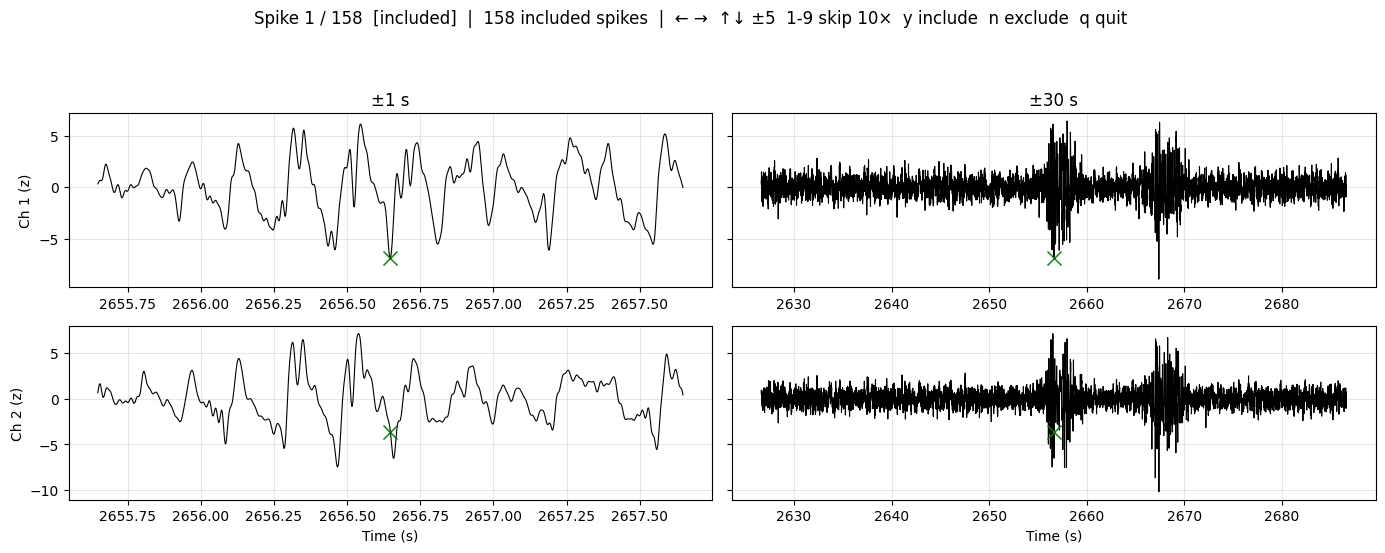

Kept 158 / 158 included spikes
Reviewing spikes for 1347 on 08_08_2025_part2


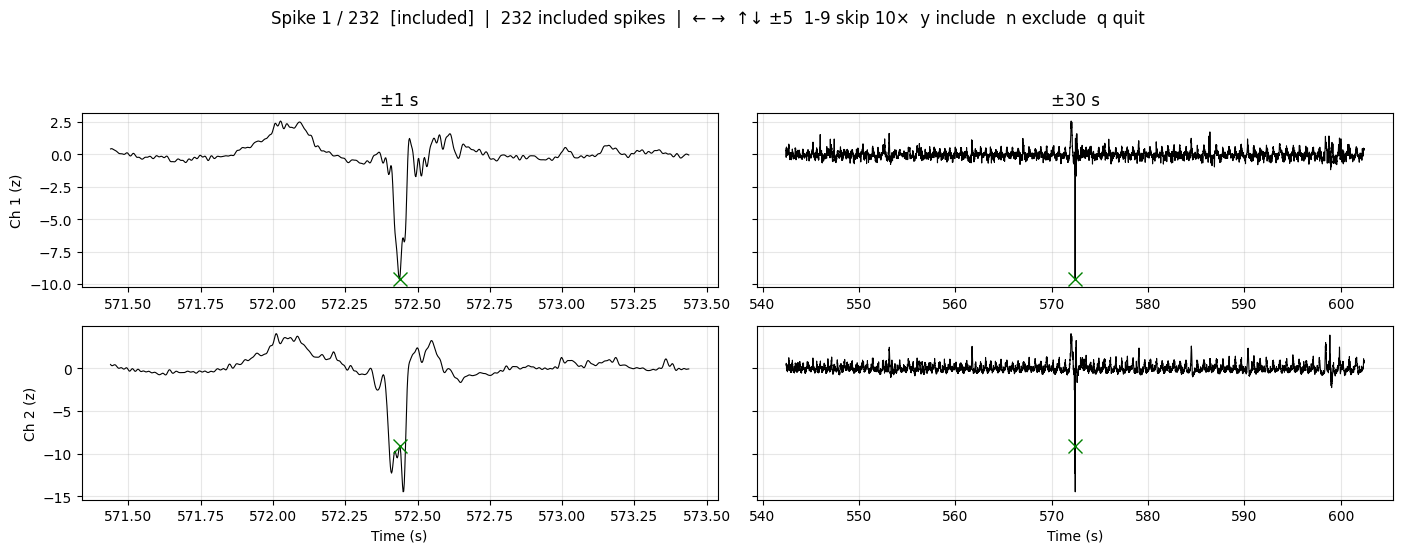

Kept 232 / 232 included spikes
Reviewing spikes for 1387 on 12_15_2025_part2


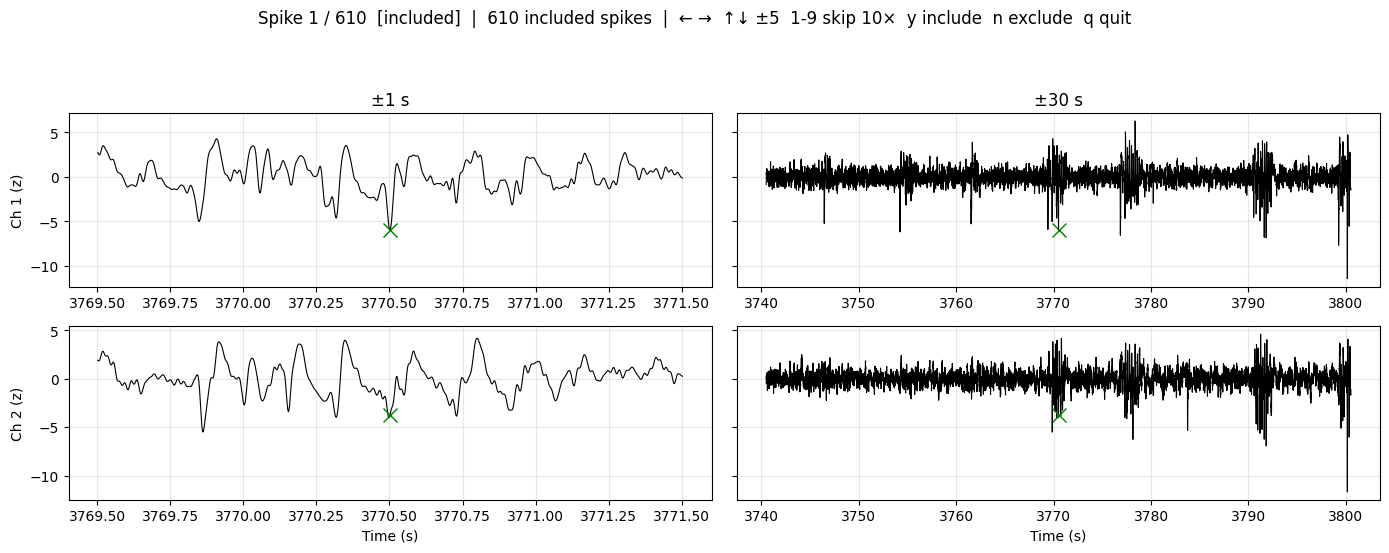

Kept 610 / 610 included spikes
Reviewing spikes for 1396 on 01_15_2026_part2


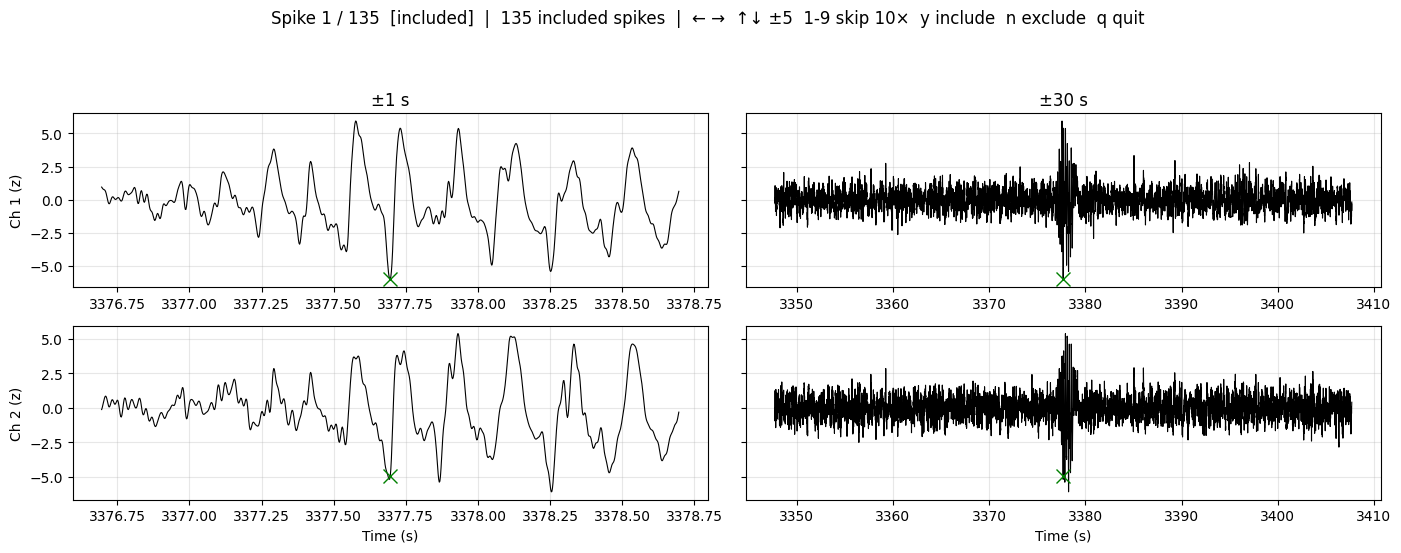

Kept 135 / 135 included spikes
Reviewing spikes for 1400 on 01_26_2026_part2


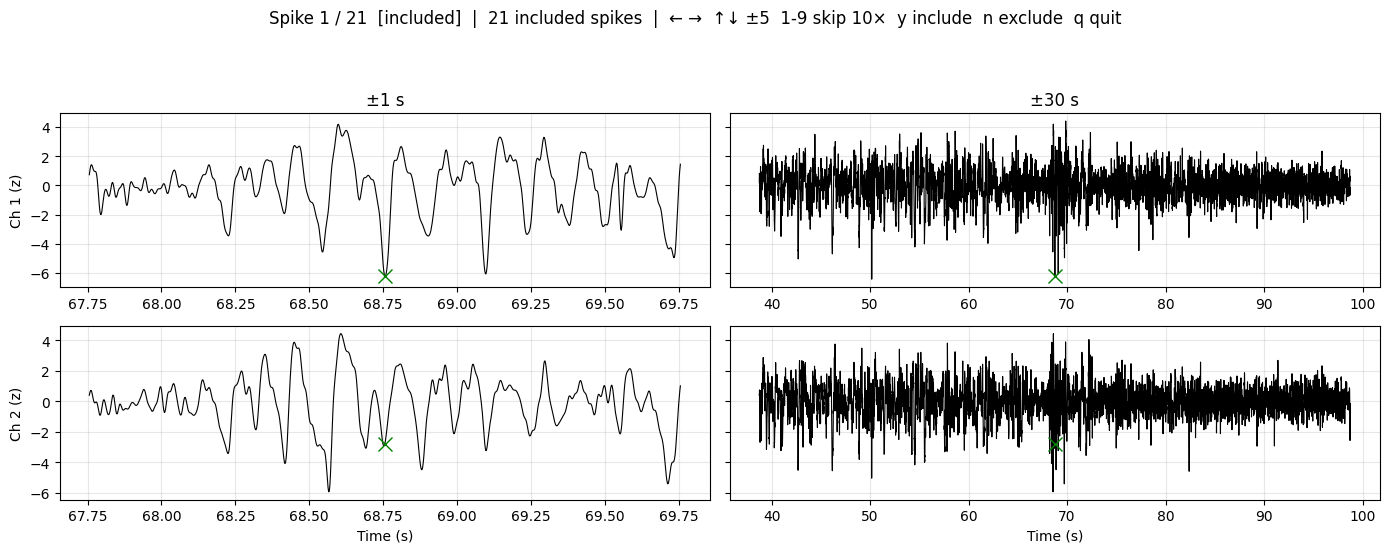

Kept 21 / 21 included spikes
Reviewing spikes for 1416 on 03_26_2026_part2


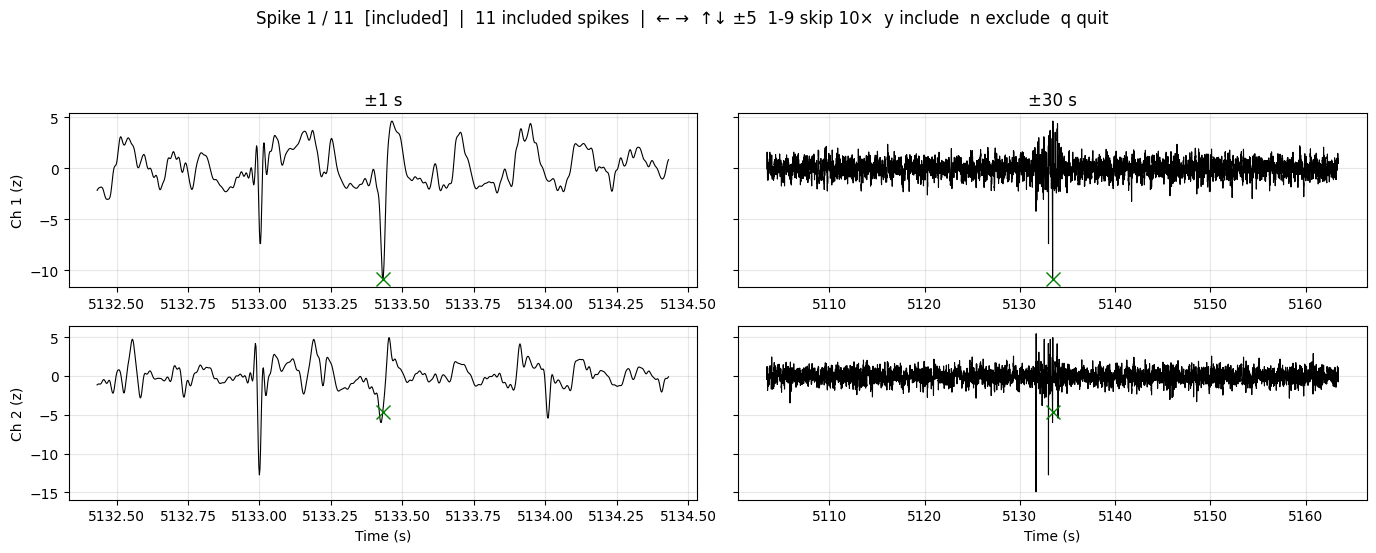

Kept 11 / 11 included spikes
Reviewing spikes for 1419 on 03_27_2026_part2


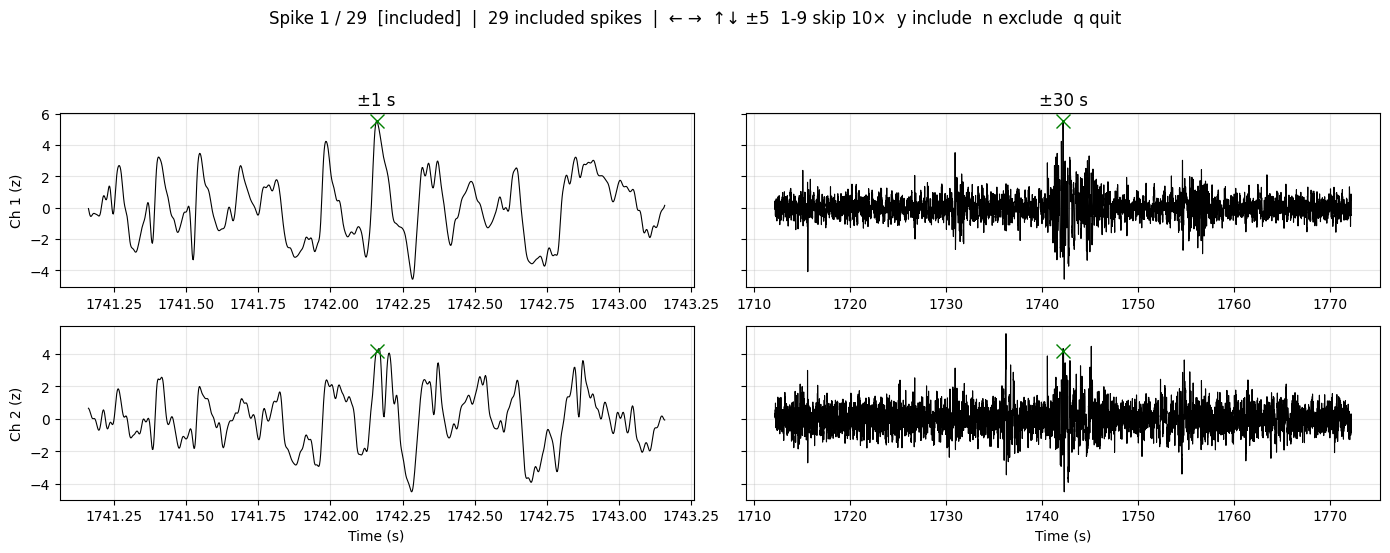

Kept 29 / 29 included spikes
Reviewing spikes for 1420 on 03_27_2026_part2


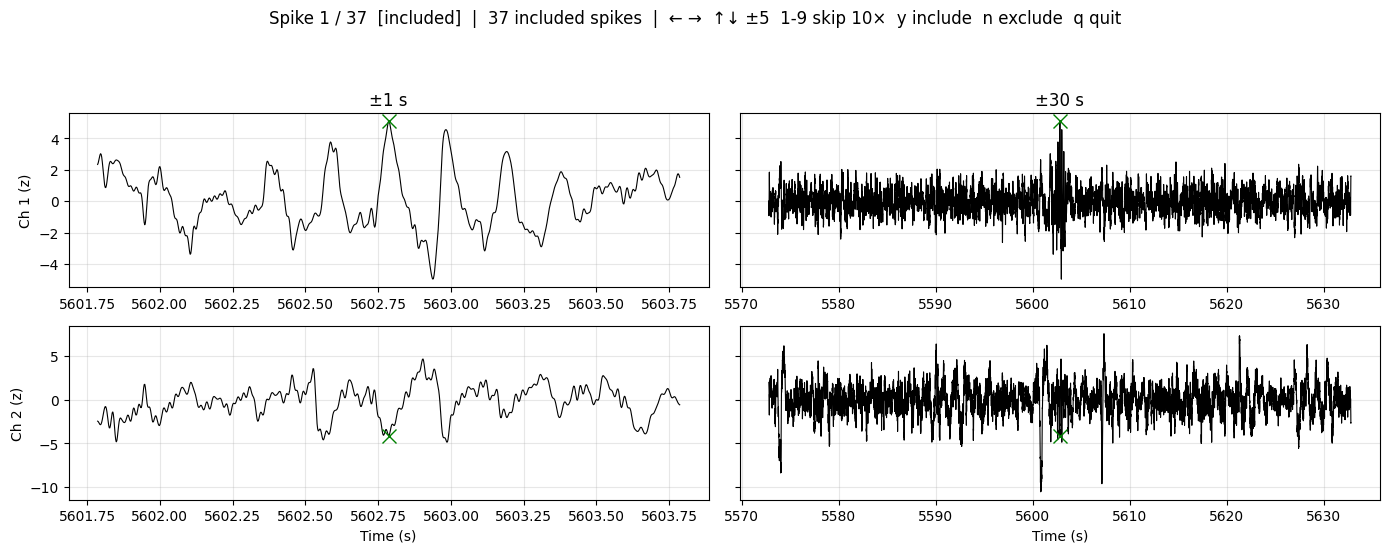

Kept 37 / 37 included spikes
Reviewing spikes for 1438 on 04_20_2026_part2


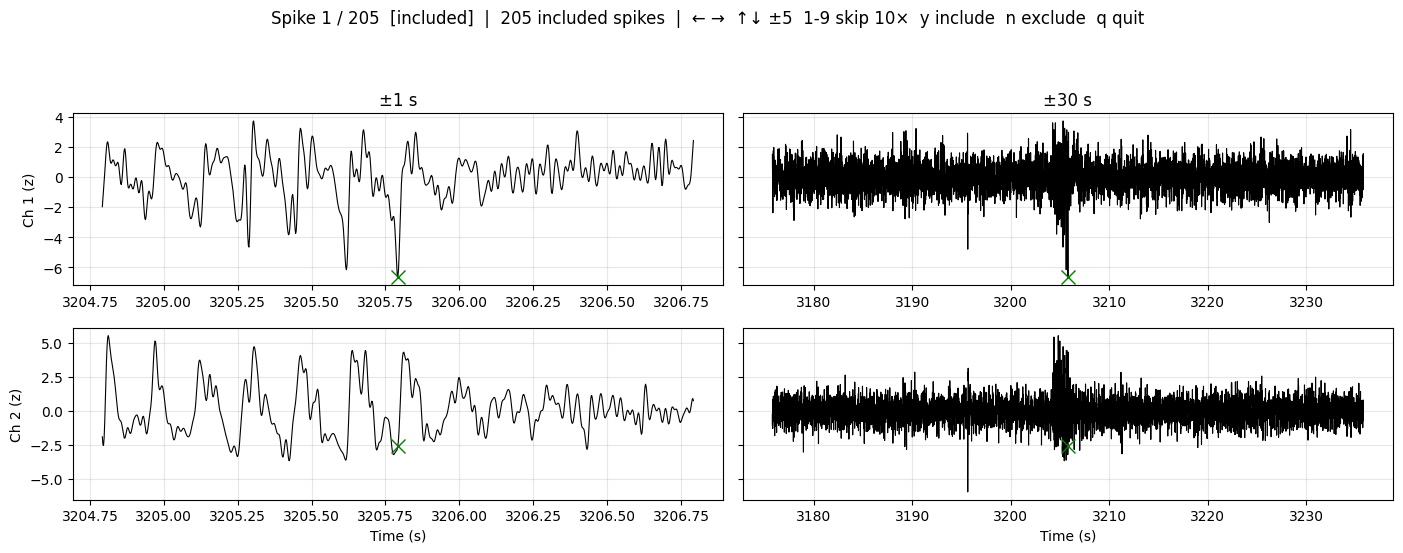

Kept 205 / 205 included spikes
Reviewing spikes for 1443 on 05_01_2026_part2


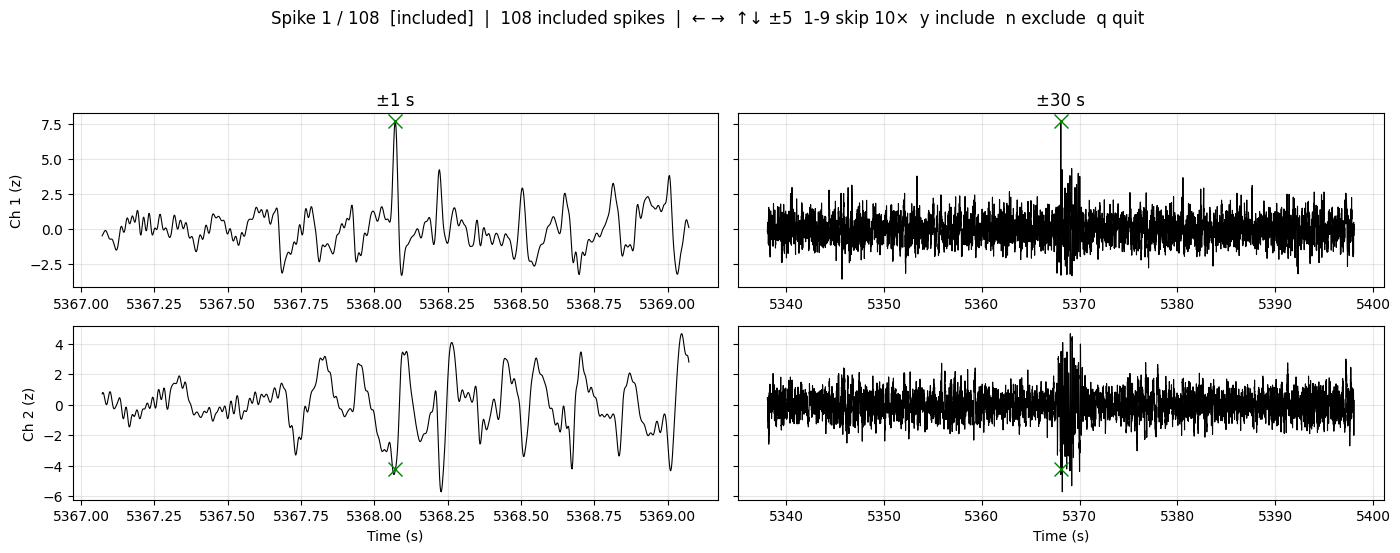

Kept 108 / 108 included spikes
Reviewing spikes for 1445 on 05_07_2026_part2


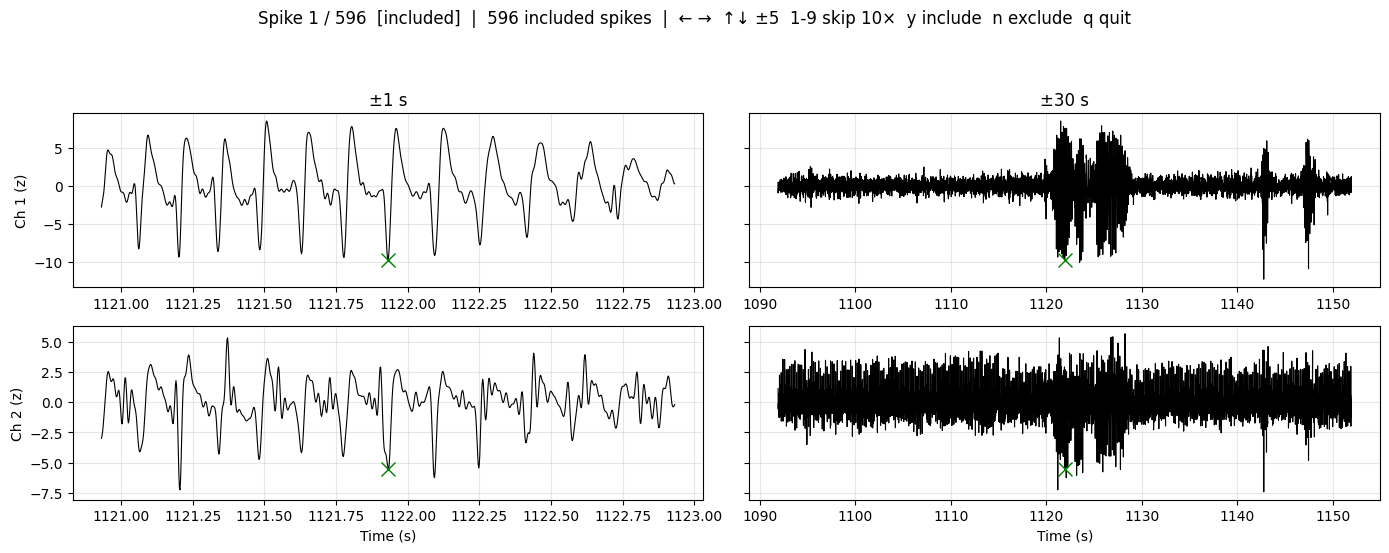

Kept 596 / 596 included spikes


In [23]:
load = False
review = True
save = False


for r in rats:
    dates = sorted(list(r.included_spikes.keys()))
    ptz_day = dates[0]
    if load:
        dates = sorted(list(r.markers.keys()))
        ptz_day = dates[1]
        r.load_spikes(ptz_day)
    if review:
        r.review_included_spikes(day=ptz_day, short_window=1, long_window=30, zscore=True)
    if save:
        r.save_spikes(ptz_day, suffix='_contralateral')

## Spike amplitude summaries

Histogram of pooled `|z|` amplitudes for one animal, then median amplitude and counts (detected vs included) for every animal.

In [29]:
%matplotlib inline
roi = rats[8]
roi.plot_spike_amplitude_hist(date='pool')

Spike amplitude histogram for 1345 on pool
No included spikes for pool


In [37]:
for r in rats:
    r.spike_summary(day='pool', avg_func=np.median, zscore=True)
    print('====================================\n')

Spike summary for 1103
pool: original spikes = 56, included spikes = 45, avg zscored V = 8.250936536613628, max zscored V = 21.89903172068893

Spike summary for 1108
pool: original spikes = 105, included spikes = 105, avg zscored V = 6.270644553562912, max zscored V = 11.38808678130766

Spike summary for 1120
pool: original spikes = 111, included spikes = 106, avg zscored V = 6.258493836679192, max zscored V = 10.61558717483967

Spike summary for 1255
pool: original spikes = 139, included spikes = 139, avg zscored V = 6.155206472543095, max zscored V = 19.7280978397569

Spike summary for 1261
pool: original spikes = 316, included spikes = 316, avg zscored V = 6.400379980367374, max zscored V = 19.767561719231875

Spike summary for 1262
pool: original spikes = 581, included spikes = 581, avg zscored V = 14.257566588031969, max zscored V = 61.56603142033556

Spike summary for 1273
pool: original spikes = 641, included spikes = 641, avg zscored V = 6.5712773434924925, max zscored V = 31.0

## Seizure RMS

Browse each Racine-labeled seizure in the MNE Qt viewer (close a window to advance), then report RMS of the longest seizure after z-scoring to that animal's baseline on the channel of interest.

In [14]:
mne.viz.set_browser_backend("qt")
for r in rats:
    if r.subject_id == '1416':
        r.plot_seizures() 

Plotting seizures for 1416
03_26_2026_part2: racine5, duration = 118.16 s  [1/1]
Channels marked as bad:
none


In [ ]:
for r in rats:
    # set channel of interest to ipsi (EEG2, idx = 1); contralateral (EEG1, idx = 0). 1103 was swapped
    r.coi = 1 if r.subject_id == '1103' else 0 
    if r.subject_id == '1402': # no baseline because eeg was too poor bilaterally, so skip
        continue
    r.seizure_rms(summary="longest", zscored=True)

Calculating RMS for 1103
05_30_2024_part2: racine6, duration = 66.42 s, RMS = 4.737
05_30_2024_part2: racine5, duration = 41.01 s, RMS = 5.343
Longest-seizure RMS for 1103: 4.736522102759473 zscored V(duration 66.42 s)

Calculating RMS for 1108
05_31_2024_part2: racine5, duration = 47.09 s, RMS = 3.76
Longest-seizure RMS for 1108: 3.7601245763942037 zscored V(duration 47.09 s)

Calculating RMS for 1120
05_31_2024_part2: racine5, duration = 157.45 s, RMS = 3.05
Longest-seizure RMS for 1120: 3.049999840921564 zscored V(duration 157.45 s)

Calculating RMS for 1255
03_07_2025_part2: racine2, duration = 26.25 s, RMS = 2.833
03_07_2025_part2: racine5, duration = 69.72 s, RMS = 3.807
03_07_2025_part2: racine4, duration = 185.89 s, RMS = 2.814
Longest-seizure RMS for 1255: 2.8138171322387375 zscored V(duration 185.89 s)

Calculating RMS for 1261
04_09_2025_part2: racine5, duration = 53.97 s, RMS = 1.96
04_09_2025_part3: racine5, duration = 116.19 s, RMS = 3.313
Longest-seizure RMS for 1261: 3.

## Manual check of RMS implementation

Sanity check on one seizure: z-score the ipsilateral channel to baseline, then compute RMS, matching `EEGSubject.seizure_rms`.

In [ ]:
roi = rats[9]
print(roi.subject_id)
ptz_day = list(roi.markers.keys())[1]
seizures = roi.get_seizure_windows(date=ptz_day)
_, s, e = seizures[2]
soi = select_data_segment(roi.preprocessed[ptz_day], s, e)

seeg = soi.get_data()[1:, :]
beeg = roi.get_baseline().get_data()[1:, :]

mu = np.mean(beeg, axis=-1, keepdims=True)
std = np.std(beeg, axis=-1, keepdims=True)

zeeg = (seeg - mu) / std

rms = np.sqrt(np.mean(zeeg**2, axis=-1))

rms

Same seizure as a ratio of raw RMS to baseline RMS (not z-scored), for comparison with the z-scored implementation above.

In [ ]:
roi = rats[9]
print(roi.subject_id)
ptz_day = list(roi.markers.keys())[1]
seizures = roi.get_seizure_windows(date=ptz_day)
_, s, e = seizures[2]
soi = select_data_segment(roi.preprocessed[ptz_day], s, e)

seeg = soi.get_data()[1:, :]
beeg = roi.get_baseline().get_data()[1:, :]

eeg_rms = np.sqrt(np.mean(seeg**2, axis=-1))
beeg_rms = np.sqrt(np.mean(beeg**2, axis=-1))

result = eeg_rms / beeg_rms

result